# Learning notebook 1: Following a withdrawal from request to evidence
**Question for this lesson:** What can a requester know after asking an automated worker to give up permission?

**Goal:** follow two saved cases and explain why the same message, “unconfirmed,” can accompany different action outcomes.

**Suggested pace:** 15–20 minutes, with no time limit. Reading alone is enough. This notebook contains no executable cells, no installation step and no experiment to launch.

### Why this question matters
An organization may authorize an assistant to perform a task, then withdraw that permission. The person asking for withdrawal needs an honest account of what happened. “We received your request” and “the action is now blocked” communicate different facts. An unclear message can leave the person relying on protection that has not been established.

Our study examines that evidence problem in a small controlled system. It does not evaluate how often people misunderstand an interface, and the requester in these cases is software rather than a recruited human participant.

### Your route
1. Meet the people and programs represented in the example.
2. Learn where these two cases came from and what their labels mean.
3. Follow the first case, **S4: confirmation withheld**, as a complete worked example.
4. Explain what the caller can know in **S5: withdrawal delivery withheld**.
5. Read its evidence, compare the cases and explain the result.
6. Use the answer notes and technical references for a deeper review.

**Research position:** the earlier local study has saved results. The separate Temporal work is preparation for a new setting. Finishing this lesson advances your understanding, not the qualification status of that new study.

[Current study-position guide](../experiments/temporal-qualification-v0.1/05_safeguard_review_and_qualification_plan.ipynb) · [Complete study report](../RESEARCH_STUDY.ipynb)
**Want the behind-the-scenes evidence?** [Technical companion: evidence and AI-use coverage](learning_02_technical_provenance.ipynb) shows what records survive, selected research decisions, and the full scripted S4/S5 worker records. It distinguishes these from research-team conversations that have not been recovered.


## 1. Put the question into a concrete setting
**Info • Revocation means withdrawing permission that was previously given.**

Imagine an assistant has permission to send a customer email. The email has not yet been sent. You change your mind and ask for that permission to be withdrawn. The important question is whether the sending system will still accept an attempt using the old permission.

This is an analogy for understanding the study. **No real customer emails were sent in these tests.** In the actual fixture, an accepted attempt recorded an inert summary in the local sink. The saved payload is `inert summary`, under the effect key `summary:task1`. That local record is the **simulated effect** discussed in this lesson.

### Meet the parts of the system
| Role | In the email analogy | In the saved study |
|---|---|---|
| Requester, called the **caller** in the records | The interface through which you ask to withdraw permission | A separate software module that sees only its allowed messages |
| **Relay** | A messenger carrying the request and returning confirmation | A program that can deliberately hold either the request or the completion message |
| **Authority** | The service responsible for deciding whether sending is still permitted | A fixed local permission authority reached through a gateway |
| **Worker** | The assistant trying to send | The program making the protected execution attempt |
| **Sink** | The place where an accepted action takes effect and is recorded | One trusted local system with a SQLite event database and simulated effect record |
| Later reviewer/checker | Someone investigating what happened | A process allowed to inspect the saved records after the run |

The gateway is the entry point to the local authority and action system. SQLite is the database used to preserve its committed events. These names matter because the caller does **not** see everything that the later checker can inspect.

### Follow the message route
```text
Caller asks for withdrawal
          ↓
Relay carries request to the local authority
          ↓
Authority installs withdrawal at the enforcement point
          ↓
Relay returns completion confirmation to caller

Separately: worker attempts the protected action at that local system.
```

This is the intended message route, not a promise that every message arrives. The experiment deliberately holds messages at selected points.

**Installed withdrawal** means the local enforcement state has changed. The **enforcement point** is where the local system checks permission. The study calls the recorded withdrawal boundary a **fence**: after that boundary, the old permission is refused at this point. The word does not mean that every process or downstream service has stopped.

The caller's final message **“unconfirmed”** means that the allowed completion evidence had not arrived before its observation window ended. An **observation window** is the bounded period covered by the case. This status describes the caller's evidence, not a hidden view of the authority.

## 2. Where S4 and S5 came from
**You are here: understanding the case labels before reading the results.**

The earlier study arranged six specific event sequences, named **S0 through S5**. “S” is the schedule label used in the protocol. The numbers identify cases; they are not research phases, difficulty levels or progress scores.

Each schedule was exercised in two paths:
- **Direct path:** a reference route to the local gateway.
- **Framework path:** a LangGraph workflow using its checkpoint-and-resume machinery.

A checkpoint saves workflow state so that execution can resume. LangGraph is the workflow framework used in these earlier cases. Both paths shared the local gateway; they were not two independent implementations of the permission mechanism. Six schedules across two paths produced 12 fixed cases.

The other schedules cover a live action with no withdrawal (S0), confirmation before the attempt (S1), an action before withdrawal installation (S2), and completion delivered after the fenced attempt (S3). This lesson concentrates on S4 and S5 because both end with the same caller message. The full protocol retains all six.

The selected cases make one distinction especially visible:

| Case label | Plain-language name | What the experiment deliberately held |
|---|---|---|
| **S4** | Confirmation withheld | The relay received completion from the authority but did not forward it to the caller |
| **S5** | Withdrawal delivery withheld | The relay did not deliver the withdrawal to the authority during the observation window |

The chosen order alone is not a finding. The records must show what the implementation actually did, and the checker must examine the caller's status separately from the action outcome.

### Where Temporal fits
**Temporal** is software for coordinating work across steps and workers, including work that waits or retries. It is a different setting planned for the next stage of this research. The framework path in S4 and S5 used **LangGraph, not Temporal**. Historical documents sometimes call that path “native”; that wording refers to the actual LangGraph integration in those documents, not a completed Temporal study.

The earlier cases used scripted model replies and simulated actions. They provide bounded evidence about this fixture's behavior, not a measurement of a live language model's judgment or production reliability.


## 3. Worked example: S4, confirmation withheld
**You are here: following one case all the way from the arranged condition to its justified conclusion.**

### Starting position
The worker has permission to perform the simulated action. The caller asks for that permission to be withdrawn. The test allows the withdrawal to reach the local authority, but deliberately holds back its completion message at the relay.

### Timeline
| Order in this case | What happened | Why it matters |
|---|---|---|
| 1 | Caller requested withdrawal | This establishes the request, not its effect |
| 2 | Authority committed the withdrawal; the saved fence sequence is 7 | The local enforcement state changed |
| 3 | Relay received the authority's response and withheld completion from the caller | The authority and caller now have different information |
| 4 | Worker attempted the protected action using the old permission | This exercises the action path after the recorded withdrawal |
| 5 | Local system recorded “denied: revoked” and zero effects | The later attempt was rejected in this case |
| 6 | Caller's observation ended without completion confirmation | Its recorded status remained unconfirmed |

Sequence 7 identifies the event's recorded order. It does not measure elapsed time.

```text
Authority: withdrawal installed → worker attempt denied → no effect recorded
Caller:    request made          → completion withheld  → UNCONFIRMED
```

### How the evidence supports the conclusion
The requester screen alone gives us uncertainty. The saved summary and post-run review report additional records: the committed withdrawal, the worker's later attempt, the local denial and the recorded effect count. Together, these support a narrow statement:

> In S4's local test, the withdrawal was installed and the later attempt was denied, while the caller still lacked confirmation.

The statement is deliberately local. It does not assert that an earlier effect was undone, every process stopped, or every external service honored the withdrawal.

### Critical-reader pause
Zero effects alone would leave the action path unclear: perhaps no attempt occurred. Here, the recorded attempt and revoked denial matter alongside the zero count. The post-run review also reports successful live controls elsewhere in the six-schedule set. This lesson reads that report; it does not repeat the audit.

### Back to the email analogy
The sending service could have blocked the old permission while the completion message to your interface was withheld. You would still lack confirmation. The local service's records could later establish the denial. This analogy explains the information gap; S4 did not send or block an actual email.

**Evidence:** the pinned summary contains matching S4 results for the direct and framework paths. The post-run review describes the deliberate completion withholding and saved-record checks. Full links appear at the end of this notebook.

## 4. Your turn: explain what the caller can know in S5
**Task • Keep the caller's evidence separate from the later reviewer's evidence.**

You now know that S5 holds delivery of the withdrawal. The caller is not told the schedule label or allowed to inspect the private relay log. It receives request acceptance and eventually an observation-end signal, with no completion confirmation.

Pause over three questions:

1. What does request acceptance establish?
2. Which part of withdrawal remains unconfirmed from the caller's perspective?
3. Which records would you request as a later reviewer to determine the action outcome?

Write a sentence or think through your answer. This is a reading activity using saved evidence.

**Hint:** acceptance describes receipt at the relay. Installation and action outcome have different evidence sources.

Continue to the timeline and compare those sources.


## 5. Inspect S5: withdrawal delivery withheld
**You are here: examining the records the later reviewer can use.**

### Starting position
The worker again has permission for the simulated action. The caller asks for withdrawal. This time, the relay accepts the request but deliberately holds its delivery to the authority through the observation window.

Relay acceptance records receipt of the request by the relay. The protocol calls it **volatile acceptance**: it is not a promise that the request will survive a restart, and it does not establish installation at the authority.

### Timeline
| Order in this case | What happened | Why it matters |
|---|---|---|
| 1 | Caller requested withdrawal and the relay accepted it | The request reached the messenger |
| 2 | Relay held delivery to the authority | The authority had not installed this withdrawal |
| 3 | Worker attempted the protected action | The existing permission still governed the attempt |
| 4 | Local system recorded one authorized simulated effect, at sequence 7 | The action outcome is positively recorded |
| 5 | Observation ended without delivery or completion confirmation | The caller remained unconfirmed |

```text
Authority: no withdrawal delivered in window → authorized simulated effect
Caller:    request accepted by relay          → UNCONFIRMED
```

### How the evidence supports the conclusion
The summary records no fence in the window, an effect-producing attempt and one effect. The post-run review describes the authorized effect and withheld delivery.

We do not infer that an action happened merely from an absent withdrawal record. The action and its effect have their own positive records. These support the bounded statement:

> In S5's observed window, the withdrawal was not delivered to the authority, and the worker produced one authorized simulated effect. The caller still lacked confirmation.

The window matters. This case does not establish that a withdrawal could never arrive later.

### Compare the cases
![Two saved cases, two information lanes. S4: local withdrawal installed, later attempt denied, zero effects; caller remains unconfirmed because relay holds completion. S5: withdrawal request held, worker acts under existing permission, one simulated effect; caller also remains unconfirmed. The comparison table gives the same information in text.](attachment:s4-s5-comparison.png)

| Question | S4: confirmation withheld | S5: withdrawal delivery withheld |
|---|---|---|
| What was withheld? | Completion message back to the caller | Withdrawal request on its way to the authority |
| Was withdrawal installed locally in the window? | Yes | No |
| What did the action record show? | Revoked denial; zero effects | Authorized simulated effect; one effect |
| What did the caller see at the end? | Unconfirmed | Unconfirmed |

The matching caller messages are the lesson. A later reviewer can distinguish these cases using records the caller did not receive. This is a difference in available evidence, not a claim about what a human believed or understood.
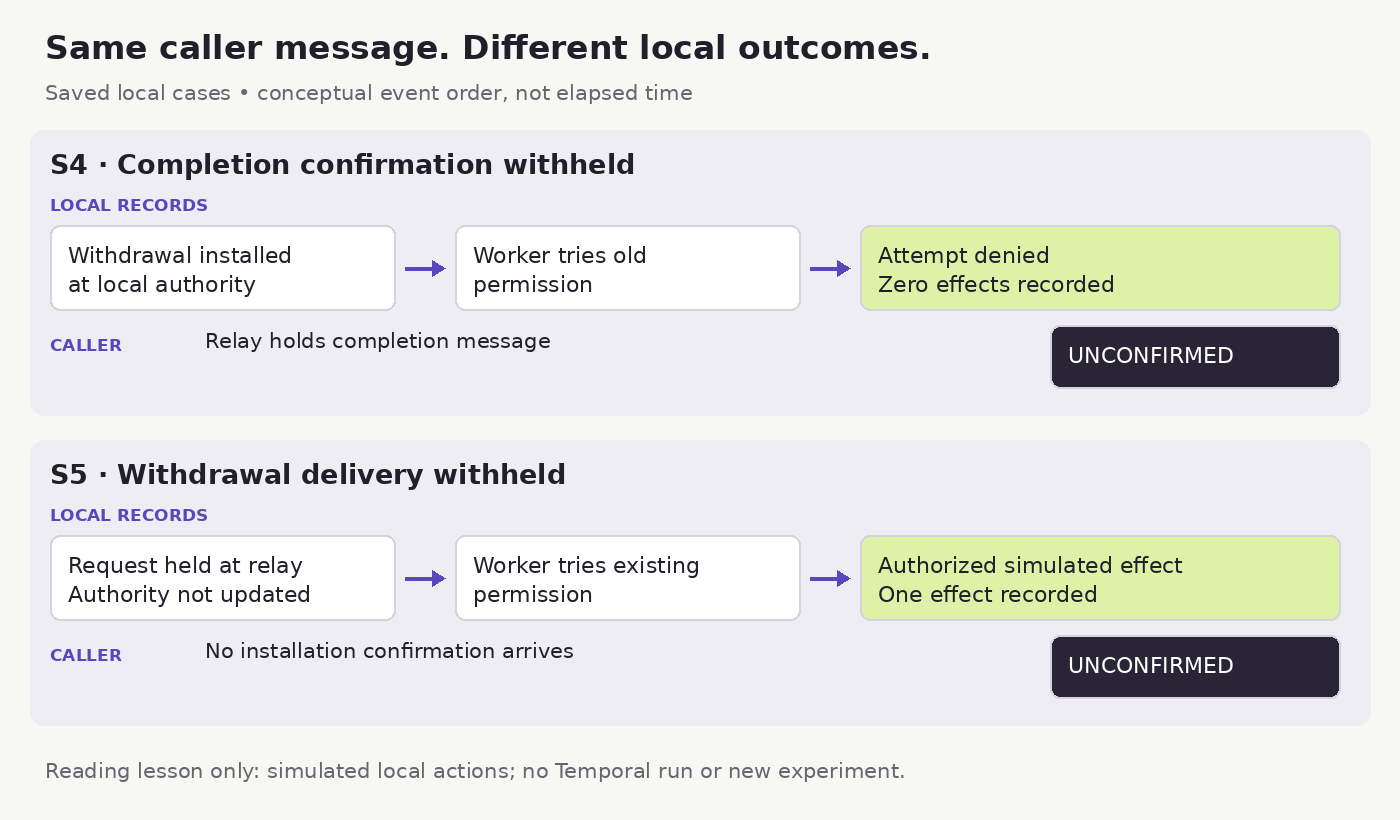

## 6. Reflection and one-sentence summary
**Reflection • Explain the finding without using the word “fence.”**

Try completing these sentences:

- “In S4, the requester did not know, but the local records showed…”
- “In S5, the requester did not know, and the local records showed…”
- “Before saying withdrawal worked, I would want evidence of…”

**One-sentence takeaway:** a request to withdraw permission, an effective withdrawal and a confirmation are different events; inspect the relevant action records rather than treating the requester's message as proof.

### Connect this to our current work
Temporal can coordinate a worker's steps, but coordination is not the same as enforcement of permission. A future Temporal study must identify where permission is checked and what records justify its conclusions. S4 and S5 teach that distinction; they do not validate the future setup.

The recent pipe/process checks address another question: whether the experimental exchange machinery handles replies, missing replies and cleanup as planned. A passing machinery check is not a result that revocation worked.

You have finished the main lesson. Answer notes and full technical references follow.

## 7. Answer notes
**Read after the activity and reflection. Use these explanations to check the evidence behind your answer.**

**What does acceptance establish?** The relay received the request. Its volatile acceptance does not establish installation at the authority or persistence through a restart.

**What remains unconfirmed for the caller?** Installation remains unconfirmed. S4 shows that withdrawal can work without confirmation reaching the requester. S5 shows the same message while withdrawal was not delivered within the observation window.

**What does S5 deliberately arrange?** The relay withholds withdrawal delivery through the observation window. It is not a measurement of how often such delivery failures occur in practice.

**What would help us distinguish the cases?** A linked record of whether withdrawal was installed at the relevant authority, the worker's attempt and its outcome, and any recorded protected effect. Also ask whether the records cover the relevant period and action. A missing record alone is not a complete answer.

**Possible reflection answer:** “The requester was uncertain in both cases. In S4, the local withdrawal and later denial were recorded. In S5, the withdrawal was not delivered during the observed window and an authorized simulated effect was recorded.”

A stronger-sounding answer is not necessarily better. The aim is to say only what the evidence supports.

## Technical references and limits
**All primary evidence remains available. This learning route does not replace the research record.**

The lesson was checked against these pinned documents:
- [Saved summary](https://github.com/node-and-norm/revocation-delegated-workflows/blob/ec186a071e81d18154b8dd3b055a757e930164c8/docs/review/WITHDRAWAL_INTERFACE_SUMMARY_v0.1.json): inspect `schedule=S4/S5` and `path=direct/framework`.
- [Post-run review](https://github.com/node-and-norm/revocation-delegated-workflows/blob/ec186a071e81d18154b8dd3b055a757e930164c8/docs/review/WITHDRAWAL_INTERFACE_POSTRUN_REVIEW_v0.1.md): case outcomes, record checks and interpretation limits.
- [Original protocol](https://github.com/node-and-norm/revocation-delegated-workflows/blob/ec186a071e81d18154b8dd3b055a757e930164c8/docs/review/WITHDRAWAL_INTERFACE_PROTOCOL_v0.1.md): fixture design; opening status is historical.
- [Saved raw archive](https://github.com/node-and-norm/revocation-delegated-workflows/blob/ec186a071e81d18154b8dd3b055a757e930164c8/archives/withdrawal_interface_study_v01_20261103.zip): locators `measured01/{direct,framework}/{S4,S5}/record.json`.
- [Evidence workbench](01_revocation_evidence_workbench.ipynb): deeper inspection route.
- [Current guide and complete technical history](../experiments/temporal-qualification-v0.1/05_safeguard_review_and_qualification_plan.ipynb).

### What was reviewed for this lesson
The author and a separately assigned AI-assisted reviewer read the pinned summary and post-run review. The revised lesson also uses the protocol's caller boundary, event ordering and case definitions. No raw SQLite database or archive was re-audited for this teaching update. The summary and review are reports of the earlier recorded work, not fresh measurements.

### Exact field reminders
Both cases store `caller_state=UNCONFIRMED_AT_OBSERVATION_END`. S4 has `fence_seq=7`, revoked denial and `effect_count=0`. S5 has `fence_seq=null`, an effect at sequence 7 and `effect_count=1`.

S5's stored `post_fence_effect_count=0` is **not applicable to a nonexistent fence in that window**. It is not evidence that a fence prevented effects.

### Additional technical boundaries
The protocol uses one fixed synthetic authority and one outstanding withdrawal. The gateway's revoke operation does not generally validate arbitrary target root/epoch bindings or echo the request ID in its response. Correlation and truthful relay behavior are bounded fixture assumptions. The caller validates its permitted completion envelope; that envelope is not a signed remote certificate.

The caller cannot inspect the sink database, private relay log, scenario label or protected-action outcome. The later checker can inspect them. Authoritative ordering comes from committed SQLite events, not from a message-send timestamp or worker output alone. The protocol's original “not yet collected” wording is historical; the later summary and post-run review report the completed collection.

The earlier framework/native path refers to LangGraph in this study, **not native Temporal**. Model replies were scripted. The fixture had one trusted local authority/sink, one root and edge, and one outstanding withdrawal. It did not establish crash recovery, distributed closure, rollback, production readiness or statistical reliability.

This is an AI-assisted educational interpretation of saved evidence, not a new experiment or independent human validation. No checker or notebook cell was run to create this lesson. Future executable teaching would need a separately reviewed and approved scope. The original experiment's records and limitations remain authoritative.

[Back to current study position](../experiments/temporal-qualification-v0.1/05_safeguard_review_and_qualification_plan.ipynb)
